In [3]:
#Canadian CPI graph

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Read the CPI data
#header=8 tells pandas that the column headings are on row 9
#since the first 8 rows contain information about the dataset
cpi_data = pd.read_csv("STATIC_INFLATIONCALC.csv", header=8)

#Display the first five rows to check that the data was loaded correctly
print(cpi_data.head())

         date  STATIC_INFLATIONCALC  Unnamed: 2  Unnamed: 3
0  1914-01-01                   6.0         NaN         NaN
1  1914-02-01                   6.0         NaN         NaN
2  1914-03-01                   6.0         NaN         NaN
3  1914-04-01                   6.0         NaN         NaN
4  1914-05-01                   5.9         NaN         NaN


In [3]:
#Select the date and CPI columns
dates = cpi_data["date"]
cpi = cpi_data["STATIC_INFLATIONCALC"]

In [4]:
#Calculate annual inflation
inflation = []

#Loop through every montly CPI observation
for i in range(len(cpi)):
    #The first 12 months do not have previous-year data
    if i < 12:
        inflation.append(None)
    else:
        #CPI for the current month
        current_cpi = cpi.iloc[i]
        #CPI for the same month last year
        previous_cpi = cpi.iloc[i - 12]
        #Calculate annual inflation
        rate = ((current_cpi/previous_cpi) - 1) * 100
        #Add the calculated inflation rate to the list
        inflation.append(rate)

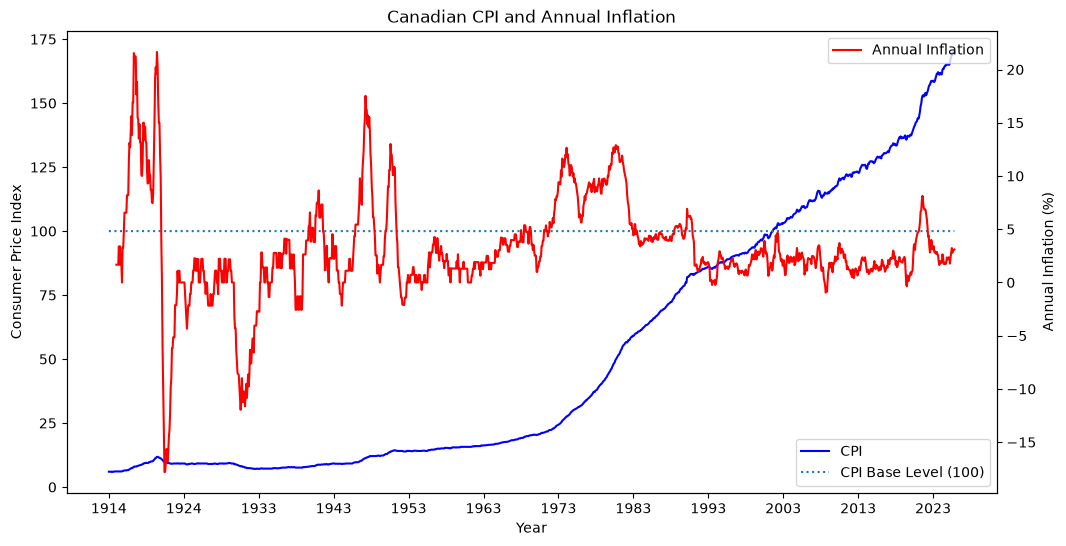

In [5]:
#Use observation numbers for the x-axis
#Each observation represents one month of CPI data
x = range(len(cpi))

#Create the graph
fig, ax1 = plt.subplots(figsize=(12,6))

#Plot CPI values against the monthly observations on the left axis
ax1.plot(x, cpi, color="blue", label="CPI")

#Add a dotted line at the CPI base level
ax1.plot(x, [100] * len(dates), ":", label="CPI Base Level (100)")

#Label the left axis
ax1.set_xlabel("Year")
ax1.set_ylabel("Consumer Price Index")

#Create the second y-axis for annual inflation
#twinx() allows both lines to share the same x-axis while using different scales on the y-axis
ax2 = ax1.twinx()

#Plot annual inflation on the right y-axis
ax2.plot(x, inflation, color="red", label="Annual Inflation")

#Label the right axis
ax2.set_ylabel("Annual Inflation (%)")

#Display a year label every ten years
positions = []
labels = []

for i in range(0, len(dates), 120):
    #Store the observation number where the label will appear
    positions.append(i)
    #Extract the year from the date using [:4]
    labels.append(dates.iloc[i][:4])

#Set the position of the labels on x-axis
ax1.set_xticks(positions)
#Display the corresponding years
ax1.set_xticklabels(labels)

#Add the title and legends
plt.title("Canadian CPI and Annual Inflation")
ax1.legend(loc="lower right")
ax2.legend(loc="upper right")

#Save the graph
plt.savefig("CPI Graph.png")

#Display the graph
plt.show()